In [2]:
import gymnasium as gym

# Initialise the environment
env = gym.make("LunarLander-v3", render_mode="human")

# Reset the environment to generate the first observation
observation, info = env.reset(seed=42)
for _ in range(1000):
    # this is where you would insert your policy
    action = env.action_space.sample()

    # step (transition) through the environment with the action
    # receiving the next observation, reward and if the episode has terminated or truncated
    observation, reward, terminated, truncated, info = env.step(action)

    # If the episode has ended then we can reset to start a new episode
    if terminated or truncated:
        observation, info = env.reset()

env.close()

## Maze Debugging

In [7]:
from pyamaze import maze
import pandas as pd
import tkinter as tk
import matplotlib.pyplot as plt

In [ ]:

tk.Tk.state = lambda self, s=None: self.wm_state('normal' if s == 'zoomed' else s)
def generate_df_maze(rows=20, cols=20, lp=80):
    # Create a Pyamaze maze
    m = maze(rows, cols)
    m.CreateMaze(loopPercent=lp)  # No loops to match a grid-like maze

    # List to store cell data
    maze_data = []
    for y in range(1, rows + 1):
        for x in range(1, cols + 1):
            cell = (x, y)
            cell_walls = m.maze_map[cell]  # Get wall info for each cell

            E = 1 if cell_walls['E'] else 0
            W = 1 if cell_walls['W'] else 0
            N = 1 if cell_walls['N'] else 0
            S = 1 if cell_walls['S'] else 0

            maze_data.append([f"({x},{y})", E, W, N, S])

    df = pd.DataFrame(maze_data, columns=["  cell  ", "E", "W", "N", "S"])
    if '  cell  ' in df.columns:
        df[['row', 'col']] = (
            df['  cell  '].astype(str)
            .str.replace(r'[()]', '', regex=True)
            .str.split(',', expand=True)
            .astype(int)
        )
    return df, m

In [3]:
# df_maze, m = generate_df_maze(
#             5,
#             5,
#             40
#         )
df_maze = pd.read_csv("data/rl_maze.csv")

In [14]:
m.run()

In [37]:
df_maze.iloc[44]

  cell      (5,5)
E               1
W               0
N               1
S               1
row             5
col             5
Name: 44, dtype: object

In [4]:
import networkx as nx
def _build_graph(df_maze):
        G = nx.Graph()
        for _, row in df_maze.iterrows():
            r, c = int(row['row']), int(row['col'])
            G.add_node((r, c))
            if row['E'] == 1:
                G.add_edge((r, c), (r, c+1))
            if row['W'] == 1:
                G.add_edge((r, c), (r, c - 1))
            if row['N'] == 1:
                G.add_edge((r, c), (r - 1, c))
            if row['S'] == 1:
                G.add_edge((r, c), (r + 1,c))
        return G

In [5]:
G = _build_graph(df_maze)

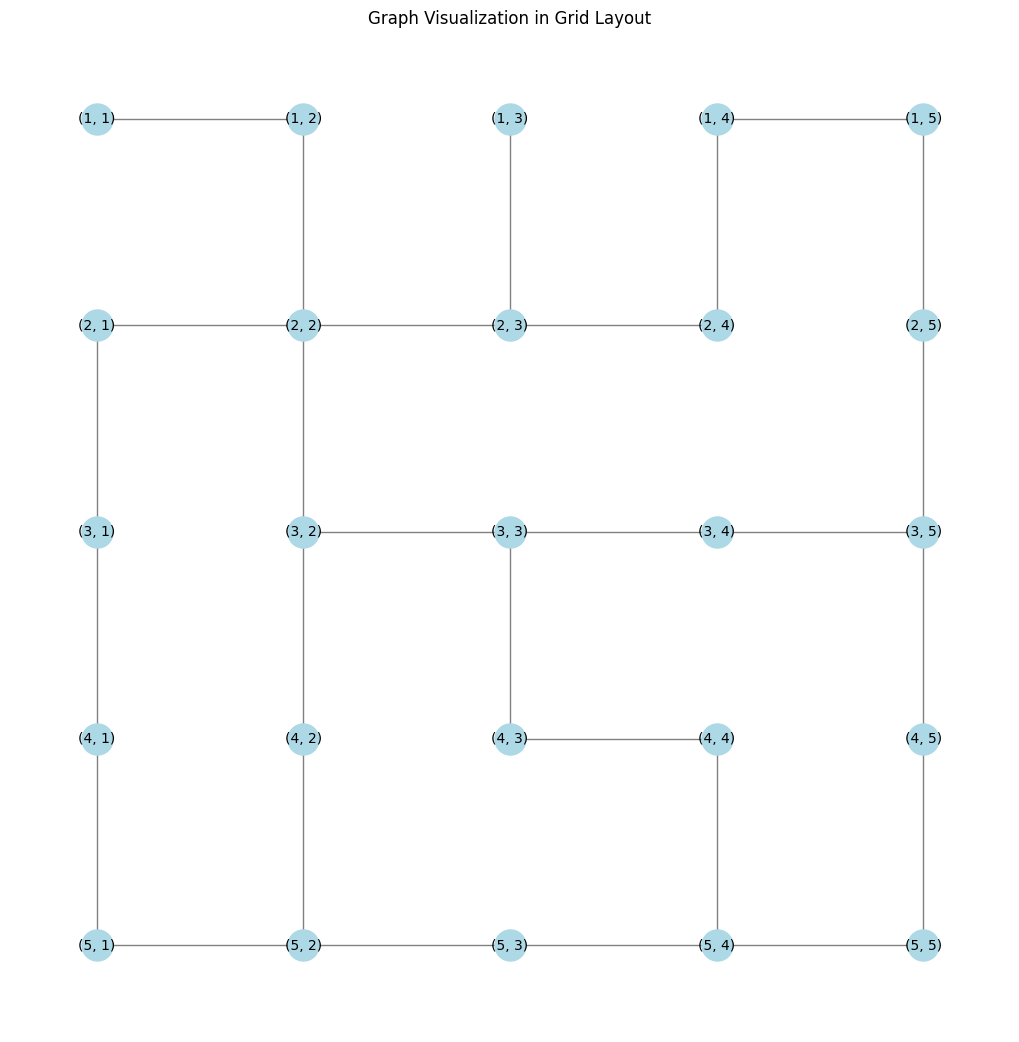

In [8]:
# Arrange nodes in a grid layout
pos = {(row['col'], row['row']): (row['row'], -row['col']) for _, row in df_maze.iterrows()}

# Draw the graph
plt.figure(figsize=(10, 10))
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=500, font_size=10, edge_color='gray')
plt.title("Graph Visualization in Grid Layout")
plt.show()

In [34]:
# Print the edges of the center node
max_row = df_maze['row'].max()
max_col = df_maze['col'].max()
center_row = max_row // 2
center_col = max_col // 2
center_node = (center_col, center_row)
edges = G.edges(center_node)
print(f"Edges of the center node {center_node}: {list(edges)}")

Edges of the center node (np.int64(5), np.int64(5)): [((np.int64(5), np.int64(5)), (4, 5)), ((np.int64(5), np.int64(5)), (5, 6)), ((np.int64(5), np.int64(5)), (6, 5))]


In [18]:
df_maze.to_csv("data/rl_maze.csv", index=False)

## Plotting the Training Log

Single Agent Working

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_results = pd.read_csv("runs/38de89a9/train_log.txt")

df_results.head()

,Episode,Total Reward,Epsilon
0,1,-2176.4,0.2000
1,2,-199.6,0.1980
2,3,-110.0,0.1960
3,4,-71.6,0.1941
4,5,-2148.2,0.1921


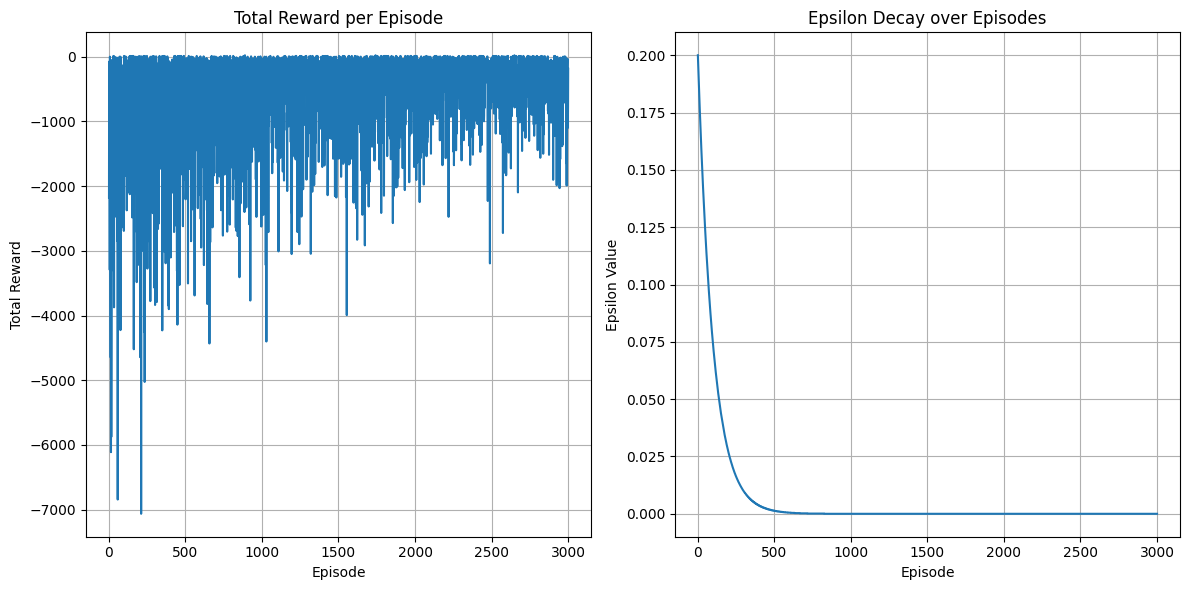

In [5]:
plt.figure(figsize=(12, 6))

# Plot 1: Total Reward over episodes
plt.subplot(1, 2, 1)
plt.plot(df_results['Episode'], df_results[' Total Reward'])
plt.title('Total Reward per Episode')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.grid(True)

# Plot 2: Epsilon over episodes
plt.subplot(1, 2, 2)
plt.plot(df_results['Episode'], df_results[' Epsilon'])
plt.title('Epsilon Decay over Episodes')
plt.xlabel('Episode')
plt.ylabel('Epsilon Value')
plt.grid(True)

plt.tight_layout()
plt.show()

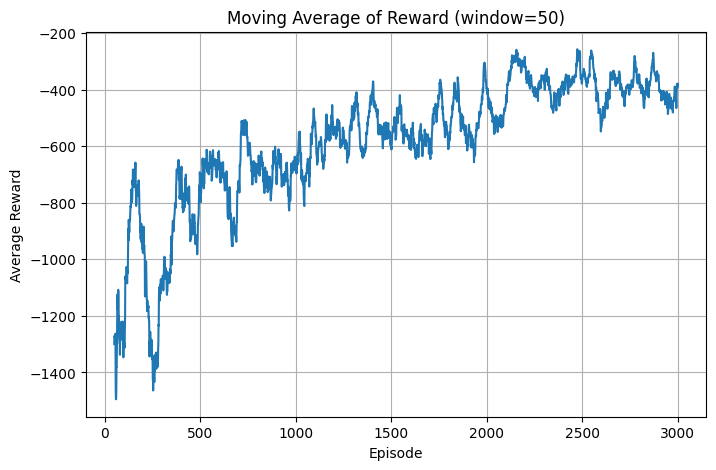

In [6]:
window_size = 50  # Adjust this for smoother or more responsive averaging
moving_avg = df_results[' Total Reward'].rolling(window=window_size).mean()

plt.figure(figsize=(8, 5))
plt.plot(df_results['Episode'][window_size-1:], moving_avg[window_size-1:])
plt.title(f'Moving Average of Reward (window={window_size})')
plt.xlabel('Episode')
plt.ylabel('Average Reward')
plt.grid(True)
plt.show()

## Visualizing Policy

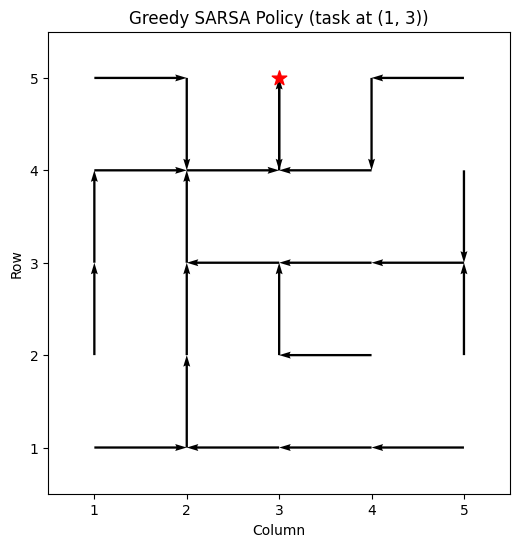

In [11]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- 1) LOAD SAVED Q‑TABLE -------------------
q_policy_path = 'runs/sarsa/train/c6f70031/policy.pkl'         # path to your pickled Q dict
with open(q_policy_path, 'rb') as f:
    Q = pickle.load(f)                  # Q: dict[state] -> np.array of action‑values

# --- 2) VISUALIZATION PARAMETERS -------------
task = (1, 3)                            # fixed task location
n_rows, n_cols = 5, 5                  # dimensions of your grid
action_map = {
    0: (-1,  0),   # up
    1: ( 0,  1),   # right
    2: ( 1,  0),   # down
    3: ( 0, -1),   # left
    # extend for any extra actions you have
}

# --- 3) BUILD VECTOR FIELD + COLOR CODES ----
X, Y, U, V, colors = [], [], [], [], []
for i in range(1,n_rows+1):
    for j in range(1,n_cols+1):
        state = ((i, j), task)
        if state in Q:
            qvals = Q[state]
            col = 'black'           # seen in training
        else:
            qvals = np.zeros(len(action_map))
            col = 'red'             # never visited during training

        best_action = int(np.argmax(qvals))
        dx, dy = action_map[best_action]

        # quiver uses (x, y) = (col, row), flipping row so (0,0) is bottom‑left
        X.append(j)
        Y.append(n_rows - i+1)   # flip row so (0,0) is at bottom‑left
        U.append(dy)
        V.append(-dx)
        colors.append(col)

# --- 4) PLOT WITH QUIVER -----------------------
plt.figure(figsize=(6,6))
plt.quiver(
    X, Y, U, V,
    angles='xy', scale_units='xy', scale=1,
    width=0.005, color=colors
)

# mark the task
tx, ty = task
plt.scatter([ty], [n_rows + 1 - tx], color='red', s=120, marker='*', label='Task')

# add legend for visited vs. unseen
visited_patch = mpatches.Patch(color='black', label='Visited in training')
unseen_patch  = mpatches.Patch(color='red',   label='Unseen state')
# plt.legend(handles=[visited_patch, unseen_patch], loc='upper right')

plt.xlim(0.5, n_cols + 0.5)
plt.ylim(0.5, n_rows + 0.5)
plt.gca().set_aspect('equal')
plt.title(f"Greedy SARSA Policy (task at {task})")
plt.xlabel("Column")
plt.ylabel("Row")
plt.show()


In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- 1) LOAD SAVED Q‑TABLE -------------------
q_policy_path = 'runs/dc7dde26/policy.pkl'
with open(q_policy_path, 'rb') as f:
    Q = pickle.load(f)  

In [2]:
Q

{(0,
  (0,
   0,
   0,
   0)): array([43.17174744, 11.66218507, 13.87518469, 12.47939052, 33.50948537]),
 (3,
  (0,
   0,
   0,
   0)): array([ 8.7424757 , 15.53471408, 11.04168073, 43.81166008, 35.14242441]),
 (1,
  (0,
   0,
   0,
   0)): array([ 7.68264283, 43.20282353, 12.11852941, 13.17038117, 29.03698188]),
 (2,
  (0,
   0,
   0,
   0)): array([15.86462279, 12.51771245, 43.95987774, 11.38042294, 33.93101094]),
 (4,
  (0,
   0,
   0,
   0)): array([24.87723429,  0.        ,  3.29708375,  2.28900483,  4.5       ])}

In [ ]:
state = ((1, 0, 2, 1),
  1,
  (1,
   3,
   3,
   1,
   2))
Q

{((1, 0, 2, 1),
  1,
  (1,
   3,
   3,
   1,
   2)): array([144.4232333 ,  74.71507351,  76.00220413,  72.72682029]),
 ((0, 2, 2, 1),
  2,
  (0,
   2,
   2,
   5,
   1)): array([109.43924619, 164.103034  , 111.36810171, 102.32052992]),
 ((0, 2, 2, 2),
  8,
  (1,
   1,
   1,
   5,
   0)): array([134.56479166,  42.32036628,  -0.28431195,  20.18387656]),
 ((0, 2, 2, 2),
  3,
  (5,
   5,
   5,
   5,
   5)): array([  2.77157318,  13.50857029, 106.82139772,  24.07340994]),
 ((0, 1, 0, 2),
  4,
  (4,
   4,
   5,
   5,
   5)): array([  5.49524568, 123.89515612,   7.62689688,  17.08354251]),
 ((0, 0, 2, 2),
  4,
  (5,
   3,
   5,
   5,
   4)): array([ 47.84082087,  42.90961525, 147.85820756,  44.81172558]),
 ((1, 0, 2, 1),
  4,
  (5,
   2,
   4,
   4,
   3)): array([ 36.83786691,   8.95433862, 146.28531244,  37.73997226]),
 ((2, 0, 2, 0),
  4,
  (5,
   1,
   3,
   3,
   2)): array([ 70.70451737,  55.94615565, 170.61502453,  47.64043009]),
 ((2, 0, 1, 2),
  4,
  (5,
   0,
   2,
   2,
   1)): arr

## Checking a log

In [7]:
import re

def extract_array(observation_line, key):
    # Example pattern: "'task_positions': array([4, 4, 4, 2, 2, 1]"
    pattern = rf"'{key}'\s*:\s*array\(\[([^\]]+)\]"
    match = re.search(pattern, observation_line)
    if match:
        nums_str = match.group(1)
        # Convert each number as an integer, ignoring extra spaces
        return [int(num.strip()) for num in nums_str.split(',')]
    return []

completed_tasks = 0
prev_task_positions = None

# Replace 'path/to/your/log_file.txt' with your actual log file path.
with open("tmp.txt", "r") as f:
    for line in f:
        # Process only observation lines 
        if line.startswith("Observation:"):
            task_positions = extract_array(line, "task_positions")
            ugv_positions = extract_array(line, "ugv_positions")
            print("ugv_positions", ugv_positions)
            print("task_positions", task_positions)
            
            if prev_task_positions is not None:
                for pos in ugv_positions:
                    if pos in prev_task_positions:
                        completed_tasks += 1
                        print("Task completed at position:", pos)
            # Update previous task_positions for next observation check
            prev_task_positions = task_positions

print("Total tasks completed:", completed_tasks)

ugv_positions [3, 2]
task_positions [5, 3, 5, 5, 5, 4]
ugv_positions [3, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 3
Task completed at position: 3
ugv_positions [4, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 4
Task completed at position: 3
ugv_positions [3, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 3
Task completed at position: 3
ugv_positions [4, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 4
Task completed at position: 3
ugv_positions [3, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 3
Task completed at position: 3
ugv_positions [4, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 4
Task completed at position: 3
ugv_positions [3, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 3
Task completed at position: 3
ugv_positions [4, 3]
task_positions [5, 3, 5, 5, 5, 4]
Task completed at position: 4
Task completed at position: 3
ugv_positions [3, 3]
task

## Checking Occupancy Grid

In [7]:
import networkx as nx
import pandas as pd
def _build_graph(df_maze):
        G = nx.Graph()
        for _, row in df_maze.iterrows():
            r, c = int(row['row']), int(row['col'])
            G.add_node((r, c))
            if row['E'] == 1:
                G.add_edge((r, c), (r, c+1), traffic=0)
            if row['W'] == 1:
                G.add_edge((r, c), (r, c - 1), traffic=0)
            if row['N'] == 1:
                G.add_edge((r, c), (r - 1, c), traffic=0)
            if row['S'] == 1:
                G.add_edge((r, c), (r + 1,c), traffic=0)

        # directions = [(-1, 0), (0, 1), (1, 0), (0, -1)]
        # for node in G.nodes:
        #     wall_distances = []
        #     for dr, dc in directions:
        #         steps = 0
        #         current = node
        #         while steps < 1:
        #             next_node = (current[0] + dr, current[1] + dc)
        #             if not G.has_edge(current, next_node):
        #                 break
        #             steps += 1
        #             current = next_node
        #         wall_distances.append(steps)
        #     G.nodes[node]['wall_distance'] = wall_distances

        # Wall Occupancy Grid 
        max_row = df_maze['row'].max()
        max_col = df_maze['col'].max()
        kernel_size = 3
        for i in range(1,max_row+1):
            for j in range(i,max_col+1):
                occupancy_grid = [0]*kernel_size*(kernel_size+1)*2
                m = len(occupancy_grid)
                for k in range(m):
                    if k<m//2:
                        row_id = k//kernel_size
                        col_id = k%kernel_size
                        row_t_diff = row_id-2
                        row_b_diff = row_id-1
                        col_diff = col_id-1
                        cell_t = (i+row_t_diff,j+col_diff)
                        cell_b = (i+row_b_diff,j+col_diff)
                        if G.has_edge(cell_t,cell_b):
                            occupancy_grid[k] = 1
                    else:
                        k_ = k-m//2
                        row_id = k_%kernel_size
                        col_id = k_//kernel_size
                        col_l_diff = col_id-2
                        col_r_diff = col_id-1
                        row_diff = row_id-1
                        cell_l = (j+row_diff,i+col_l_diff)
                        cell_r = (j+row_diff,i+col_r_diff)
                        if G.has_edge(cell_l,cell_r):
                            occupancy_grid[k] = 1
                G.nodes[(i,j)]['occupancy_grid'] = occupancy_grid

        return G

In [8]:
df_maze = pd.read_csv("data/rl_maze.csv")
G = _build_graph(df_maze)

In [9]:
G.nodes[(2,2)]['occupancy_grid']

[0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1]

In [6]:
i,j = 2,2
kernel_size = 3
occupancy_grid = [0]*kernel_size*(kernel_size+1)*2
m = len(occupancy_grid)
for k in range(m):
    if k<m//2:
        row_id = k//kernel_size
        col_id = k%kernel_size
        row_t_diff = row_id-2
        row_b_diff = row_id-1
        col_diff = col_id-1
        cell_t = (i+row_t_diff,j+col_diff)
        cell_b = (i+row_b_diff,j+col_diff)
        if G.has_edge(cell_t,cell_b):
            occupancy_grid[k] = 1
    else:
        k_ = k-m//2
        print(k_)
        row_id = k_%kernel_size
        col_id = k_//kernel_size
        print(row_id,col_id)
        col_l_diff = col_id-2
        col_r_diff = col_id-1
        row_diff = row_id-1
        cell_l = (j+row_diff,i+col_l_diff)
        cell_r = (j+row_diff,i+col_r_diff)
        print(cell_l,cell_r)
        if G.has_edge(cell_l,cell_r):
            occupancy_grid[k] = 1
G.nodes[(i,j)]['occupancy_grid'] = occupancy_grid

0
0 0
(1, 0) (1, 1)
1
1 0
(2, 0) (2, 1)
2
2 0
(3, 0) (3, 1)
3
0 1
(1, 1) (1, 2)
4
1 1
(2, 1) (2, 2)
5
2 1
(3, 1) (3, 2)
6
0 2
(1, 2) (1, 3)
7
1 2
(2, 2) (2, 3)
8
2 2
(3, 2) (3, 3)
9
0 3
(1, 3) (1, 4)
10
1 3
(2, 3) (2, 4)
11
2 3
(3, 3) (3, 4)


# Checking if a State is in a Polcy

In [1]:
import pickle
import ast

# Prompt the user for the pickle file path and state tuple
policy_path = "runs/sarsa/c00d345d/policy.pkl"
state = ((3, 1, 3, 1, 5), (0, 0, 0, 0))

# Convert the input string to a tuple safely
try:
    # state = ast.literal_eval(state_input)
    if not isinstance(state, tuple):
        raise ValueError("Input is not a tuple.")
except Exception as e:
    print("Invalid state tuple input:", e)
    raise

# Load the policy from the provided pickle file
try:
    with open(policy_path, 'rb') as f:
        policy = pickle.load(f)
except Exception as e:
    print(f"Error loading policy from {policy_path}: {e}")
    raise

# Check if the state is in the policy dictionary
if state in policy:
    print(f"State {state} is present in the policy pickle file.")
    print(f"Action values: {policy[state]}")
else:
    print(f"State {state} is NOT present in the policy pickle file.")

State ((3, 1, 3, 1, 5), (0, 0, 0, 0)) is present in the policy pickle file.
Action values: [1174.07049016  324.39017714   83.22633506  453.48865802  272.12460621]


# Checking Atari Env

In [3]:
import gymnasium as gym
env = gym.make("PongNoFrameskip-v4", render_mode="rgb_array")
env = gym.wrappers.RecordEpisodeStatistics(env)

# observation, info = env.reset(seed=42)
# done = False
# while True:
#     action = env.action_space.sample()
#     observation, reward, terminated, truncated, info = env.step(action)
#     if terminated or truncated:
#         observation, info = env.reset()
# env.close()

In [5]:
env.observation_space.shape

(210, 160, 3)

# Checking RecordStat Wrapper

In [1]:
import gymnasium as gym
import yaml

import envs

In [11]:
config = yaml.safe_load(open("runs/dijkstra/config.yaml"))
env = gym.make("LMDEnv-v0", config=config, render_mode="print")
env = gym.wrappers.RecordEpisodeStatistics(env)

In [12]:
obs, info = env.reset(seed=42)

/home/shinobi-owl/anaconda3/envs/clean_rl/lib/python3.10/site-packages/gymnasium/utils/passive_env_checker.py:188: UserWarning: WARN: The obs returned by the `reset()` method is not within the observation space.
  logger.warn(f"{pre} is not within the observation space.")


In [31]:
info

{'time_elapsed': 350.0,
 'current_timestep': 7,
 'num_tasks_completed': 2,
 'total_ev_distance': 350.0,
 'total_energy_consumed': 350.0,
 'avg_task_completion_time': 300.0,
 'active_tasks': [(8, 6)],
 'red_roads': [((2, 5), (3, 5)),
  ((3, 5), (3, 6)),
  ((3, 5), (4, 5)),
  ((4, 5), (5, 5)),
  ((3, 6), (3, 7)),
  ((3, 6), (4, 6)),
  ((5, 6), (4, 6)),
  ((3, 7), (2, 7)),
  ((4, 6), (4, 7)),
  ((4, 7), (5, 7))],
 'yellow_roads': [((3, 4), (3, 5)),
  ((2, 5), (2, 6)),
  ((4, 4), (4, 5)),
  ((1, 6), (2, 6)),
  ((5, 5), (5, 6)),
  ((3, 7), (3, 8)),
  ((4, 7), (4, 8))],
 'episode': {'r': array([45.], dtype=float32),
  'l': array([6], dtype=int32),
  't': array([117.31592], dtype=float32)}}

In [28]:
obs

array([101, 101,   0,   2,   1,   0,   0,   0,   0], dtype=int32)

In [30]:
obs, reward, terminated, truncated, info = env.step(2)

In [10]:
env.close()

# SUMO

## SumoNetVis

In [1]:
import networkx as nx
import SumoNetVis
import matplotlib.pyplot as plt

In [2]:
def build_graph(map):
    G = nx.Graph()
    net = SumoNetVis.Net(map)

    juncs = net.junctions

    # Add nodes for each edge in the SUMO network
    for edge in net.edges.values():
        # Get the from and to junctions for this edge
        if edge.from_junction_id is None or edge.to_junction_id is None:
            continue
        from_junction = edge.from_junction_id
        to_junction = edge.to_junction_id

        G.add_node(from_junction, x=juncs[from_junction].x, y=juncs[from_junction].y)
        G.add_node(to_junction, x=juncs[to_junction].x, y=juncs[to_junction].y)

        # Add edge between the junctions
        G.add_edge(from_junction, to_junction, traffic=0)#, weight=edge.getLength())

    # Calculate all shortest path lengths for observation space
    all_shortest_path_lengths = dict(nx.all_pairs_shortest_path_length(G))

    return G, all_shortest_path_lengths

In [3]:
G = build_graph("data/slc/slc.net.xml")[0]

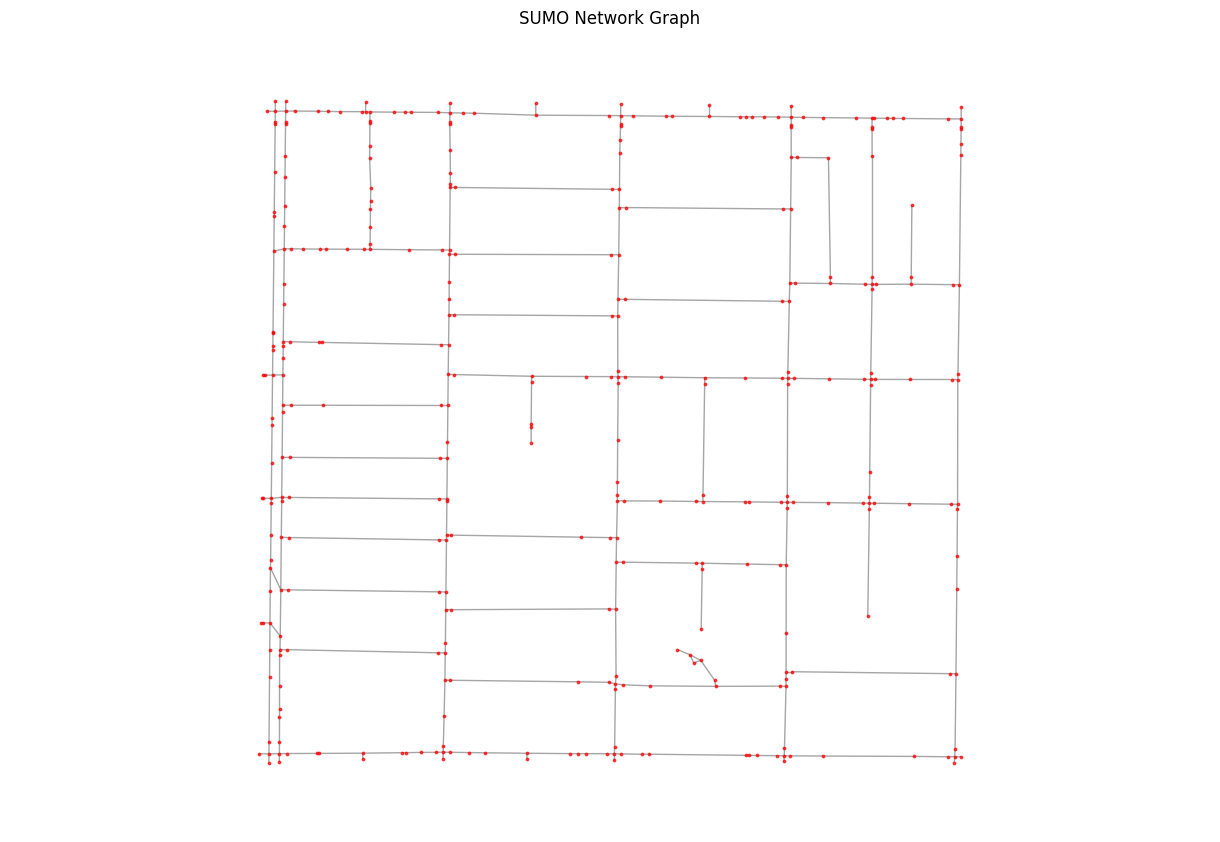

In [4]:
# Extract node positions from x,y attributes
pos = {node: (data['x'], data['y']) for node, data in G.nodes(data=True)}

# Create the plot
plt.figure(figsize=(12, 8))
nx.draw(G, pos, with_labels=False, node_color='red', node_size=3, 
    font_size=8, edge_color='gray', alpha=0.7)
plt.title("SUMO Network Graph")
plt.axis('equal')
plt.show()

## Sumo Grid Generating and Traffic

In [ ]:
#!/usr/bin/env python3
# TraCI-only edge monitor. Connects to an already running SUMO (started with --remote-port).
# Reports: per-step veh count, mean speed, occupancy; plus cumulative entrants and flow (veh/h).

import argparse
import time
from statistics import mean

import traci

def avg_edge_occupancy(edge_id: str) -> float:
    """Return average occupancy (0..1) across all lanes of edge."""
    lane_ids = traci.edge.getLaneIDs(edge_id)
    if not lane_ids:
        return 0.0
    vals = [traci.lane.getLastStepOccupancy(l) for l in lane_ids]  # fraction 0..1
    return sum(vals) / len(vals)

def main():
    ap = argparse.ArgumentParser(description="Monitor traffic on a SUMO edge via TraCI.")
    ap.add_argument("--host", default="127.0.0.1")
    ap.add_argument("--port", type=int, default=8813, help="SUMO --remote-port")
    ap.add_argument("--edge", required=True, help="Target edge ID (not an internal ':' edge)")
    ap.add_argument("--duration", type=int, default=1000, help="Seconds to monitor")
    ap.add_argument("--print-every", type=int, default=1, help="Print interval (steps)")
    args = ap.parse_args()

    print(f"Connecting to SUMO at {args.host}:{args.port} ...")
    conn = traci.connect(args.port, args.host)
    traci.switch(conn.getLabel())

    # Validate edge
    if args.edge not in traci.edge.getIDList():
        raise SystemExit(f"Edge '{args.edge}' not found in network.")

    # Collectors
    entrants = 0                        # vehicles that *entered* the edge (flow)
    prev_on_edge = set()                # vehicles present on edge in previous step
    speeds = []                         # mean speed time series
    counts = []                         # vehicle count time series
    occs = []                           # occupancy time series
    step = 0

    # Optional: read step length to scale results correctly
    # (you set it with --step-length when starting SUMO)
    # We’ll assume 1s if not available.
    try:
        step_length = traci.simulation.getDeltaT() / 1000.0  # ms -> s
    except Exception:
        step_length = 1.0

    print(f"Monitoring edge '{args.edge}' for {args.duration}s (step={step_length}s) ...")

    # Advance until we cover the desired window
    end_time = traci.simulation.getTime() + args.duration
    while traci.simulation.getTime() < end_time or traci.simulation.getMinExpectedNumber() > 0:
        traci.simulationStep()

        # Vehicles currently on edge
        now_on_edge = set(traci.edge.getLastStepVehicleIDs(args.edge))
        count = len(now_on_edge)
        counts.append(count)

        # Entrants = vehicles that were not on the edge last step
        step_entrants = len(now_on_edge - prev_on_edge)
        entrants += step_entrants
        prev_on_edge = now_on_edge

        # Mean speed (m/s) for vehicles observed on edge in the last step
        mean_speed = traci.edge.getLastStepMeanSpeed(args.edge) if count > 0 else 0.0
        speeds.append(mean_speed)

        # Occupancy (0..1), averaged across lanes
        occ = avg_edge_occupancy(args.edge)
        occs.append(occ)

        if (step % args.print_every) == 0:
            print(
                f"[t={int(traci.simulation.getTime()):4d}] "
                f"count={count:3d}  entrants+{step_entrants:2d}  "
                f"meanSpeed={mean_speed:6.2f} m/s  occ={occ:.3f}"
            )
        step += 1

        # If you started SUMO with a very small --step-length, this small sleep
        # makes the log readable; otherwise you can remove it.
        # time.sleep(0.0)

    # Window length in hours for flow computation
    window_s = args.duration
    window_h = max(window_s, 1e-6) / 3600.0
    flow_veh_per_h = entrants / window_h

    print("\n=== Summary ===")
    print(f"Edge:         {args.edge}")
    print(f"Duration:     {args.duration} s")
    print(f"Step length:  {step_length} s")
    print(f"Avg count:    {mean(counts):.2f} veh")
    print(f"Avg speed:    {mean(speeds):.2f} m/s")
    print(f"Avg occup.:   {mean(occs):.3f} (fraction)")
    print(f"Cumulative entrants: {entrants} veh")
    print(f"Flow:         {flow_veh_per_h:.1f} veh/h")

    traci.close()

if __name__ == "__main__":
    main()


TraCIException: Invalid type 'passenger' for vehicle 'veh0'.

In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- 1) LOAD SAVED Q‑TABLE -------------------
q_policy_path = 'runs/aa63c747/policy.pkl'         # path to your pickled Q dict
with open(q_policy_path, 'rb') as f:
    Q = pickle.load(f)                  # Q: dict[state] -> np.array of action‑values


In [2]:
Q

{(23, 24): array([48.11243699,  0.        ,  0.        ,  0.        ]),
 (18,
  24): array([-1.02009680e-08, -8.81835407e-13,  4.94975335e+01,  0.00000000e+00]),
 (13,
  24): array([-8.62822687e-06, -9.27440030e-08, -1.17983413e-04,  4.86387046e+01]),
 (8,
  24): array([-1.08404931e-04, -1.38411704e-08, -2.17340692e-06,  4.61596187e+01]),
 (7,
  24): array([-1.16803579e-05, -1.13245940e-07,  3.61132185e+01, -7.13729186e-12]),
 (2,
  24): array([-1.32313500e-02, -1.16712415e-04,  7.14137757e+00, -1.50000000e+00]),
 (1,
  24): array([-1.20285000e-01, -1.15545291e-05,  6.21848760e-01, -1.50000000e+00]),
 (0,
  24): array([-1.02950854e-06, -1.29692918e-04, -4.06500000e+00, -2.85000013e+00]),
 (3,
  24): array([-1.17891329e-03, -1.66669797e-03,  1.35910838e+01, -2.85000000e+00]),
 (6,
  24): array([-1.19093589e-02, -2.51395650e-02,  1.75433480e+01, -9.79817119e-13]),
 (4, 24): array([-0.13365   ,  0.88191272, -2.85011671, -1.5       ]),
 (9, 24): array([-0.14458915, 10.91847408, -0.13365   

# Build Graph from Sumo Traci with sidewalks

In [1]:
import numpy as np
import networkx as nx
import traci

In [2]:
def build_graph():
    G = nx.DiGraph()

    # Get all edges (skip internal)
    edge_ids = [e for e in traci.edge.getIDList() if not e.startswith(":")]

    for eid in edge_ids:
        from_node = traci.edge.getFromJunction(eid)
        to_node = traci.edge.getToJunction(eid)

        lid = f"{eid}_0"  # Assume single lane per edge for simplicity
        length = traci.lane.getLength(lid)
        speed = traci.edge.getLastStepMeanSpeed(eid)

        # Add nodes (junctions)
        fx, fy = traci.junction.getPosition(from_node)
        tx, ty = traci.junction.getPosition(to_node)
        G.add_node(from_node, x=fx, y=fy)
        G.add_node(to_node, x=tx, y=ty)

        # Add directed edge with attributes
        G.add_edge(
            from_node,
            to_node,
            id=eid,
            length=length,
            speed=speed,
            weight=length / speed if speed > 0 else float("inf")
        )

    all_shortest_path_lengths = dict(nx.all_pairs_shortest_path_length(G))
    return G, all_shortest_path_lengths


In [3]:
Sumo_config = [
    'sumo',
    '-c', "data/grid/grid.sumocfg",
    '--step-length', '1',
    '--start'
]
traci.start(Sumo_config)

# Maze State
# G, all_shortest_path_lengths = build_graph() # Rebuild graph with new maze

 Retrying in 1 seconds


(22, 'SUMO 1.24.0')

In [4]:
all_edges = traci.edge.getIDList()

In [6]:
traci.close()

Step #0.00 (0ms ?*RT. ?UPS, TraCI: 133818ms, vehicles TOT 0 ACT 0 BUF 0)                 
